# Schelling segregation experiment: acceptance, density, and convergence

This notebook analyzes the uploaded NetLogo BehaviorSpace table. It checks the experimental design, summarizes final outcomes and variation across repetitions, and asks whether greater acceptance of mixed neighborhoods reduces residential segregation.

**Main result:** lower similarity requirements reduce final local similarity among converged runs. At threshold 80, low final similarity accompanies widespread dissatisfaction and failure to converge, so it must not be interpreted as a stable integrated outcome.

Run the notebook beside the supplied CSV. Requires Python, pandas, NumPy, and Matplotlib. All charts and tables below are already populated. No source data are modified.

In [1]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 160)
DATA = Path('Segregation_ontology experiment-table.csv')
# Locate the header rather than assuming a fixed number of metadata lines.
with DATA.open(encoding='utf-8-sig', newline='') as f:
    rows = list(csv.reader(f))
header = next(i for i, row in enumerate(rows) if row and row[0] == '[run number]')
metadata = rows[:header]
df = pd.read_csv(DATA, skiprows=header).rename(columns={
    '[run number]':'run', '%-similar-wanted':'threshold', '[step]':'step',
    'calculate-percent-similar':'similar', 'calculate-percent-unhappy':'unhappy',
    'all? citizens [happy?]':'converged'})
df['converged'] = df['converged'].astype(str).str.lower().map({'true':True, 'false':False})
df['capped'] = (df['ticks'] == 1000) & ~df['converged']
df['termination'] = np.where(df['converged'], 'Converged', np.where(df['capped'], 'Capped', 'Other'))
print('Export metadata:', metadata)
display(df.head())

Export metadata: [['BehaviorSpace results (NetLogo 7.0.3)', 'Table version 2.0'], ['Segregation_ontology.nlogox'], ['experiment'], ['10/14/2026 01:32:21:867 -0500'], ['min-pxcor', 'max-pxcor', 'min-pycor', 'max-pycor'], ['-25', '25', '-25', '25']]


,run,threshold,density,step,similar,unhappy,ticks,converged,capped,termination
0,6,10,70,2,51.322180,0.0,2,True,False,Converged
1,1,10,70,2,53.679907,0.0,2,True,False,Converged
2,7,10,70,2,53.020962,0.0,2,True,False,Converged
3,4,10,70,2,51.478363,0.0,2,True,False,Converged
4,2,10,70,2,52.366528,0.0,2,True,False,Converged


## 1. Verify the experiment

Expected design: 3 densities × 5 thresholds × 20 repetitions = 300 final observations. Run identifiers need not appear in numerical order because BehaviorSpace may complete runs in parallel. A Boolean all-happy flag determines convergence; ticks alone do not establish it.

In [2]:
expected = pd.MultiIndex.from_product([[70,85,95],[10,30,50,70,80]], names=['density','threshold'])
counts = df.groupby(['density','threshold']).size().reindex(expected, fill_value=0)
checks = pd.Series({
    '300 observations':len(df)==300,
    '300 unique runs numbered 1–300':set(df.run)==set(range(1,301)) and df.run.is_unique,
    'No missing values':not df.isna().any().any(),
    'No duplicate records':not df.duplicated().any(),
    'Exact parameter grid':set(zip(df.density,df.threshold))==set(expected),
    '20 observations per combination':counts.eq(20).all(),
    'Recorded step equals ticks':df.step.eq(df.ticks).all(),
    'Percentages within 0–100':df[['similar','unhappy']].ge(0).all().all() and df[['similar','unhappy']].le(100).all().all(),
    'Zero unhappy agrees with all-happy':df.unhappy.eq(0).eq(df.converged).all(),
    'All nonconverged observations at cap':df.loc[~df.converged,'ticks'].eq(1000).all(),
    'No ticks beyond cap':df.ticks.le(1000).all()})
display(checks.rename('passed').to_frame())
assert checks.all(), 'Investigate failed checks before interpreting results.'
display(counts.unstack('threshold'))
display(pd.crosstab(df.converged, df.ticks.eq(1000), rownames=['all happy'], colnames=['at 1000 ticks']))
display(df.termination.value_counts().rename('runs').to_frame())

,passed
300 observations,True
300 unique runs numbered 1–300,True
No missing values,True
No duplicate records,True
Exact parameter grid,True
20 observations per combination,True
Recorded step equals ticks,True
Percentages within 0–100,True
Zero unhappy agrees with all-happy,True
All nonconverged observations at cap,True


threshold,10,30,50,70,80
density,,,,,
70,20,20,20,20,20
85,20,20,20,20,20
95,20,20,20,20,20


at 1000 ticks,False,True
all happy,,
False,0,76
True,224,0


,runs
termination,
Converged,224
Capped,76


## 2. Final outcomes and variability

Each mean weights the 20 runs equally. Standard deviations describe variation between runs, in percentage points for the percentage metrics. The table includes capped endpoints; the convergence columns must be read alongside the means.

In [3]:
summary = df.groupby(['density','threshold']).agg(
    n=('run','size'), similar_mean=('similar','mean'), similar_sd=('similar','std'),
    similar_min=('similar','min'), similar_max=('similar','max'),
    unhappy_mean=('unhappy','mean'), unhappy_sd=('unhappy','std'),
    converged=('converged','sum'), capped=('capped','sum'),
    ticks_mean=('ticks','mean'), ticks_median=('ticks','median'),
    ticks_min=('ticks','min'), ticks_max=('ticks','max'))
summary['convergence_pct']=100*summary.converged/summary.n
display(summary.round(3))

n  similar_mean  similar_sd  similar_min  similar_max  unhappy_mean  unhappy_sd  converged  capped  ticks_mean  ticks_median  ticks_min  \
density threshold                                                                                                                                             
70      10         20        52.425       0.866       50.900       53.823         0.000       0.000         20       0        2.25           2.0          2   
        30         20        72.813       1.089       71.274       75.276         0.000       0.000         20       0       10.40          10.5          8   
        50         20        88.524       0.942       86.369       90.524         0.000       0.000         20       0       15.45          14.0         10   
        70         20        99.717       0.080       99.506       99.825         0.000       0.000         20       0       50.30          50.0         36   
        80         20        53.801       1.074       51.432       55.525        82.921       1.646          0      20     1000.00        1000.0       1000   
85      10         20        51.265       0.678       50.007       52.443         0.000       0.000         20       0        1.70           2.0          1   
        30         20        73.759       1.307       71.282       76.840         0.000       0.000         20       0       13.30          13.0         10   
        50         20        87.777       0.807       86.167       89.665         0.000       0.000         20       0       18.00          18.0         14   
        70         20        99.675       0.062       99.552       99.775         0.000       0.000         20       0       79.85          77.0         59   
        80         20        51.606       0.822       50.146       53.251        89.920       1.416          0      20     1000.00        1000.0       1000   
95      10         20        50.611       0.373       49.889       51.222         0.000       0.000         20       0        1.35           1.0          1   
        30         20        75.141       0.860       73.818       76.639         0.000       0.000         20       0       17.25          15.0         10   
        50         20        87.292       0.871       85.491       89.625         0.000       0.000         20       0       23.15          23.0         16   
        70         20        99.284       0.483       98.195       99.854         0.828       0.696          4      16      968.05        1000.0        676   
        80         20        50.826       0.577       49.719       52.046        94.287       1.015          0      20     1000.00        1000.0       1000   

                   ticks_max  convergence_pct  
density threshold                              
70      10                 3            100.0  
        30                15            100.0  
        50                25            100.0  
        70                64            100.0  
        80              1000              0.0  
85      10                 3            100.0  
        30                19            100.0  
        50                25            100.0  
        70               113            100.0  
        80              1000              0.0  
95      10                 3            100.0  
        30                63            100.0  
        50                34            100.0  
        70              1000             20.0  
        80              1000              0.0

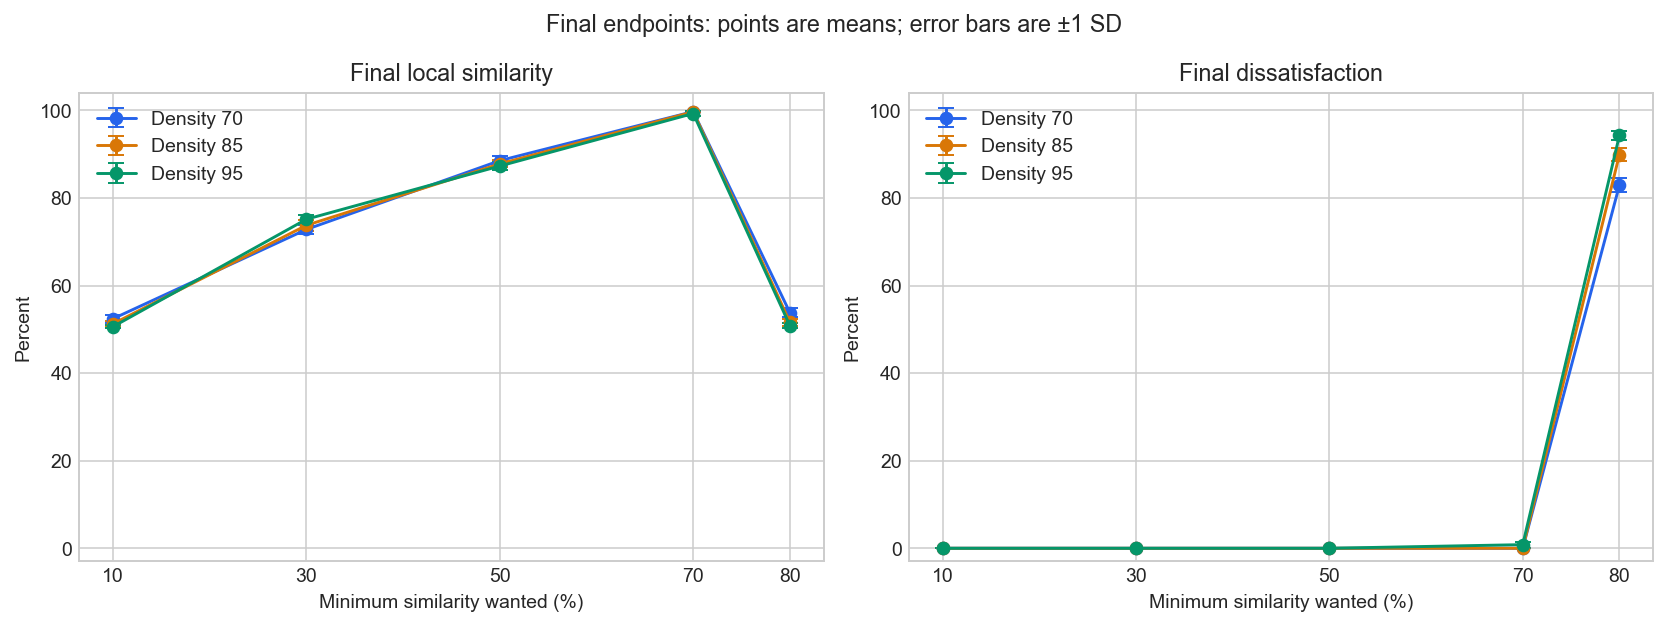

In [4]:
fig, axes = plt.subplots(1,2, figsize=(12,4.5))
colors = {70:'#2563eb',85:'#d97706',95:'#059669'}
for density, group in summary.groupby(level='density'):
    group=group.droplevel('density')
    for ax, metric in zip(axes,['similar','unhappy']):
        ax.errorbar(group.index, group[metric+'_mean'], yerr=group[metric+'_sd'],
                    marker='o', capsize=4, label=f'Density {density}', color=colors[density])
for ax,title in zip(axes,['Final local similarity','Final dissatisfaction']):
    ax.set(title=title, xlabel='Minimum similarity wanted (%)', ylabel='Percent', ylim=(-3,104), xticks=[10,30,50,70,80])
    ax.legend()
fig.suptitle('Final endpoints: points are means; error bars are ±1 SD')
fig.tight_layout()
plt.show()

The sharp drop in similarity from threshold 70 to 80 is accompanied by 83–94% dissatisfaction. All threshold-80 observations are capped. These endpoints do not demonstrate an integrated equilibrium.

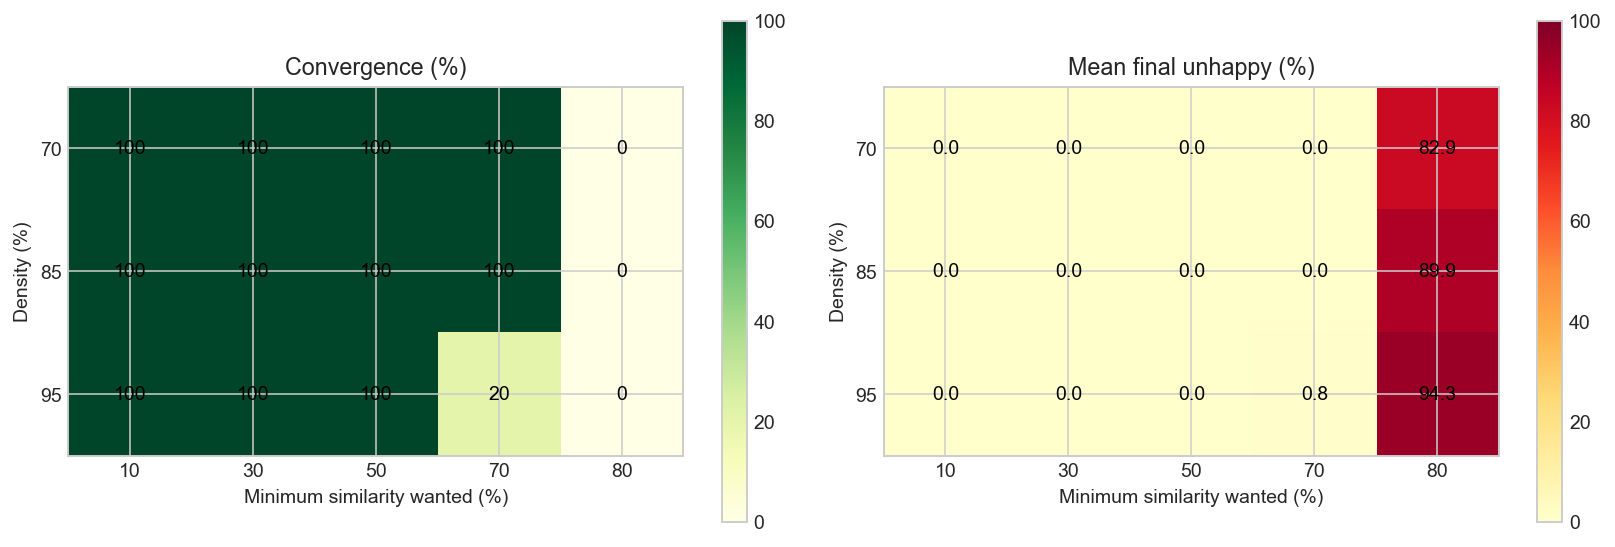

In [5]:
fig, axes=plt.subplots(1,2,figsize=(12,4))
for ax,col,title,fmt in [(axes[0],'convergence_pct','Convergence (%)','.0f'),(axes[1],'unhappy_mean','Mean final unhappy (%)','.1f')]:
    table=summary[col].unstack('threshold')
    image=ax.imshow(table, vmin=0,vmax=100,cmap='YlOrRd' if col=='unhappy_mean' else 'YlGn')
    ax.set(xticks=range(5),xticklabels=table.columns,yticks=range(3),yticklabels=table.index,
           xlabel='Minimum similarity wanted (%)',ylabel='Density (%)',title=title)
    for i in range(3):
        for j in range(5): ax.text(j,i,format(table.iloc[i,j],fmt),ha='center',va='center',color='black')
    fig.colorbar(image,ax=ax)
fig.tight_layout()
plt.show()

## 3. Time to satisfaction and the cap

Converged-only tick summaries describe successful runs. They exclude failures and therefore cannot summarize the entire experiment's speed. Capped runs are right-censored for time to universal satisfaction: their eventual convergence time is unknown, and some might never converge.

count    mean  median  min  max
density threshold                                 
70      10            20    2.25     2.0    2    3
        30            20   10.40    10.5    8   15
        50            20   15.45    14.0   10   25
        70            20   50.30    50.0   36   64
85      10            20    1.70     2.0    1    3
        30            20   13.30    13.0   10   19
        50            20   18.00    18.0   14   25
        70            20   79.85    77.0   59  113
95      10            20    1.35     1.0    1    3
        30            20   17.25    15.0   10   63
        50            20   23.15    23.0   16   34
        70             4  840.25   852.0  676  981

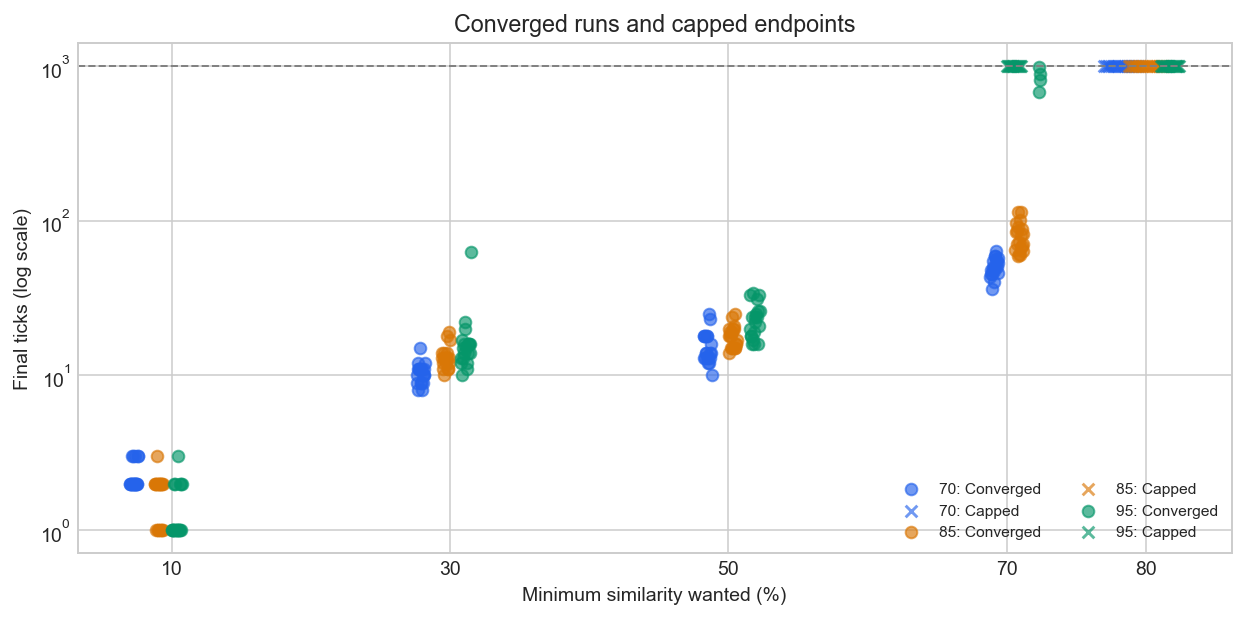

In [6]:
successful = df[df.converged].groupby(['density','threshold']).ticks.agg(['count','mean','median','min','max'])
display(successful.round(2))
fig,ax=plt.subplots(figsize=(9,4.5))
for density,g in df.groupby('density'):
    for status,marker in [('Converged','o'),('Capped','x')]:
        h=g[g.termination==status]
        # Deterministic horizontal offsets expose overlapping repetitions.
        offsets=np.linspace(-1.2,1.2,len(h)) if len(h) else np.array([])
        ax.scatter(h.threshold+(density-85)/15*1.8+offsets,h.ticks,
                   marker=marker,color=colors[density],alpha=.65,label=f'{density}: {status}')
ax.axhline(1000,color='gray',linestyle='--',linewidth=1)
ax.set(yscale='log',xlabel='Minimum similarity wanted (%)',ylabel='Final ticks (log scale)',
       xticks=[10,30,50,70,80],title='Converged runs and capped endpoints')
ax.legend(fontsize=8,ncol=2)
fig.tight_layout()
plt.show()

## 4. Quantify the acceptance effect

Lower thresholds represent greater acceptance. Thresholds 10, 30, and 50 converge in every run at every density, providing comparisons unaffected by cap failures. Independent-run approximate 95% intervals below use the mean difference ±1.96 × its standard error. These are descriptive normal approximations, not paired-seed estimates or simultaneous intervals.

In [7]:
contrasts=[]
for density in [70,85,95]:
    for higher,lower in [(30,10),(50,30),(50,10)]:
        a=df[(df.density==density)&(df.threshold==higher)].similar
        b=df[(df.density==density)&(df.threshold==lower)].similar
        reduction=a.mean()-b.mean()
        se=np.sqrt(a.var(ddof=1)/len(a)+b.var(ddof=1)/len(b))
        contrasts.append({'density':density,'threshold_change':f'{higher} → {lower}',
                          'similarity_reduction_pp':reduction,'approx_95_low':reduction-1.96*se,
                          'approx_95_high':reduction+1.96*se})
display(pd.DataFrame(contrasts).round(2))
# Density effects vary with the preference threshold.
density_contrast=summary.xs(95,level='density')[['similar_mean','unhappy_mean','convergence_pct']]-summary.xs(70,level='density')[['similar_mean','unhappy_mean','convergence_pct']]
display(density_contrast.rename(columns=lambda c:c+'_95_minus_70_pp').round(2))

,density,threshold_change,similarity_reduction_pp,approx_95_low,approx_95_high
0,70,30 → 10,20.39,19.78,21.00
1,70,50 → 30,15.71,15.08,16.34
2,70,50 → 10,36.10,35.54,36.66
3,85,30 → 10,22.49,21.85,23.14
4,85,50 → 30,14.02,13.34,14.69
5,85,50 → 10,36.51,36.05,36.97
6,95,30 → 10,24.53,24.12,24.94
7,95,50 → 30,12.15,11.61,12.69
8,95,50 → 10,36.68,36.27,37.10


,similar_mean_95_minus_70_pp,unhappy_mean_95_minus_70_pp,convergence_pct_95_minus_70_pp
threshold,,,
10,-1.81,0.00,0.0
30,2.33,0.00,0.0
50,-1.23,0.00,0.0
70,-0.43,0.83,-80.0
80,-2.98,11.37,0.0


## 5. Separate stable outcomes from unresolved endpoints

This separation prevents low similarity in a dissatisfied capped run from being confused with successful integration. At density 95 and threshold 70, the converged-only mean is based on just four successful runs and is subject to selection.

runs  similar_mean  unhappy_mean  ticks_mean
density threshold termination                                              
70      10        Converged      20        52.425         0.000        2.25
        30        Converged      20        72.813         0.000       10.40
        50        Converged      20        88.524         0.000       15.45
        70        Converged      20        99.717         0.000       50.30
        80        Capped         20        53.801        82.921     1000.00
85      10        Converged      20        51.265         0.000        1.70
        30        Converged      20        73.759         0.000       13.30
        50        Converged      20        87.777         0.000       18.00
        70        Converged      20        99.675         0.000       79.85
        80        Capped         20        51.606        89.920     1000.00
95      10        Converged      20        50.611         0.000        1.35
        30        Converged      20        75.141         0.000       17.25
        50        Converged      20        87.292         0.000       23.15
        70        Capped         16        99.150         1.035     1000.00
                  Converged       4        99.819         0.000      840.25
        80        Capped         20        50.826        94.287     1000.00

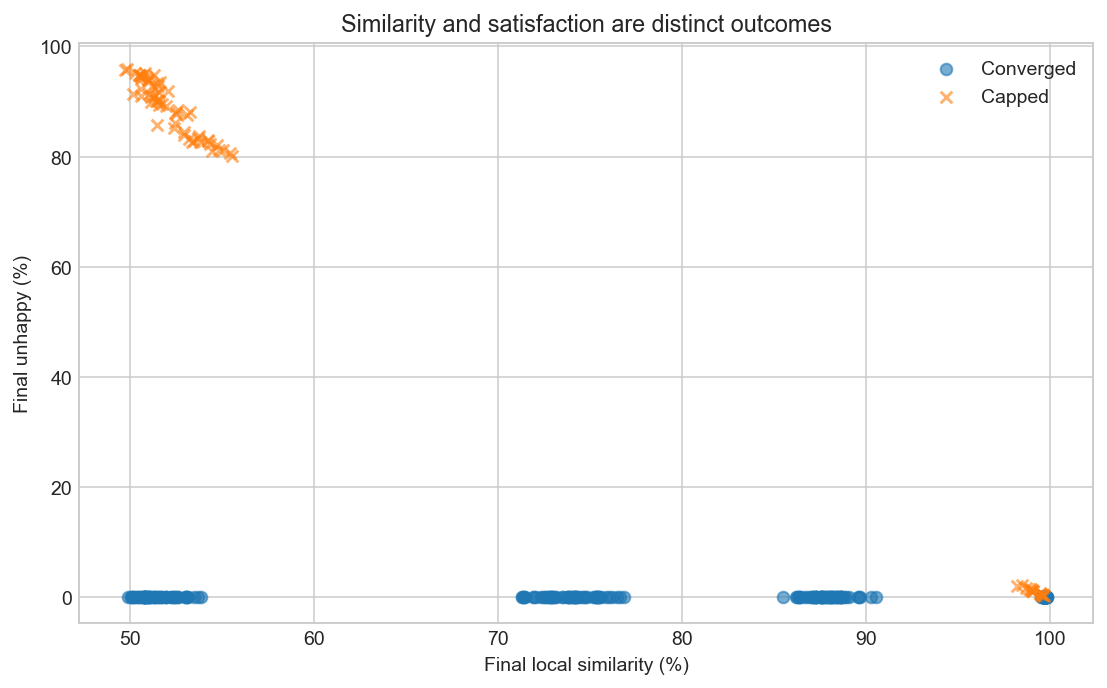

In [8]:
display(df.groupby(['density','threshold','termination']).agg(
    runs=('run','size'),similar_mean=('similar','mean'),unhappy_mean=('unhappy','mean'),
    ticks_mean=('ticks','mean')).round(3))
fig,ax=plt.subplots(figsize=(8,5))
for status,marker in [('Converged','o'),('Capped','x')]:
    h=df[df.termination==status]
    ax.scatter(h.similar,h.unhappy,marker=marker,alpha=.6,label=status)
ax.set(xlabel='Final local similarity (%)',ylabel='Final unhappy (%)',
       title='Similarity and satisfaction are distinct outcomes')
ax.legend()
fig.tight_layout()
plt.show()

## Interpretation for the policy question

- **Greater acceptance reduces local sorting in this model.** Reducing the similarity requirement from 50% to 10% lowers final similarity by approximately 36–37 percentage points at every density, with all runs converging.
- **Satisfaction does not imply integration.** A 30% requirement produces about 73–75% similarity; a 50% requirement produces about 87–89%, despite universal satisfaction.
- **Density changes the ability to settle.** At threshold 70, densities 70 and 85 converge in all repetitions; density 95 converges in only four of twenty. Increasing density has relatively small, threshold-dependent effects on similarity at thresholds 10–50.
- **Threshold 80 is an unresolved regime.** All sixty runs reach 1,000 ticks with high dissatisfaction. Its low local similarity cannot support a claim of stable integration.

### Caveats and useful follow-up experiments

The CSV contains final endpoints, not trajectories. It cannot show whether capped runs are gradually approaching satisfaction or repeatedly rearranging. The all-happy criterion identifies satisfaction-based termination, not every possible definition of equilibrium. `% Similar` measures local same-group composition, not all dimensions of residential segregation. Without inspecting model code, this analysis does not assume a particular neighborhood weighting, movement rule, treatment of isolated agents, or population balance.

There are only twenty repetitions per combination. Their small dispersion in similarity does not establish robustness to other model assumptions. Random seeds are not recorded in this table, so paired comparisons and exact reproduction of the original runs are unavailable. Roughly 50% similarity can be consistent with random mixing for balanced groups, but population composition and an appropriate random baseline must be checked before making that claim.

Changing a preference threshold is a hypothetical mechanism, not an evaluated real-world policy. A policy claim would require evidence about how an intervention changes preferences or feasible residential choices.

Useful extensions: record trajectories for capped regimes; extend the horizon; explore thresholds between 70 and 80 and densities between 85 and 95; record seeds and initial group shares; compare against random-mixing baselines and additional segregation measures; test alternative relocation and vacancy rules.